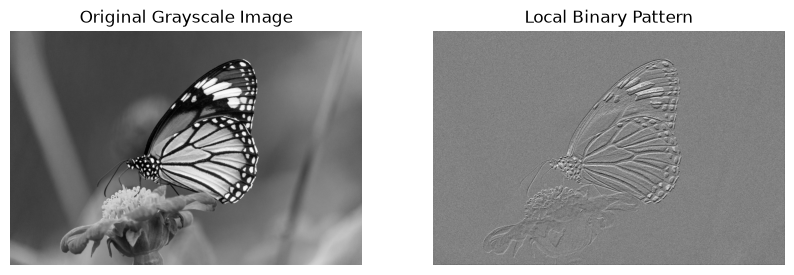

In [1]:
#Write a program to implement the local binary pattern on gray scale image.
import cv2
import matplotlib.pyplot as plt
from skimage.feature import local_binary_pattern

# Read grayscale image
img = cv2.imread("image.jpg", 0)

# Set parameters
radius = 1
points = 8 * radius

# Apply Local Binary Pattern
lbp = local_binary_pattern(img, points, radius, method="default")

# Display images
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(lbp, cmap="gray")
plt.title("Local Binary Pattern")
plt.axis("off")

plt.show()

Enter filter size (3 or 5):  5


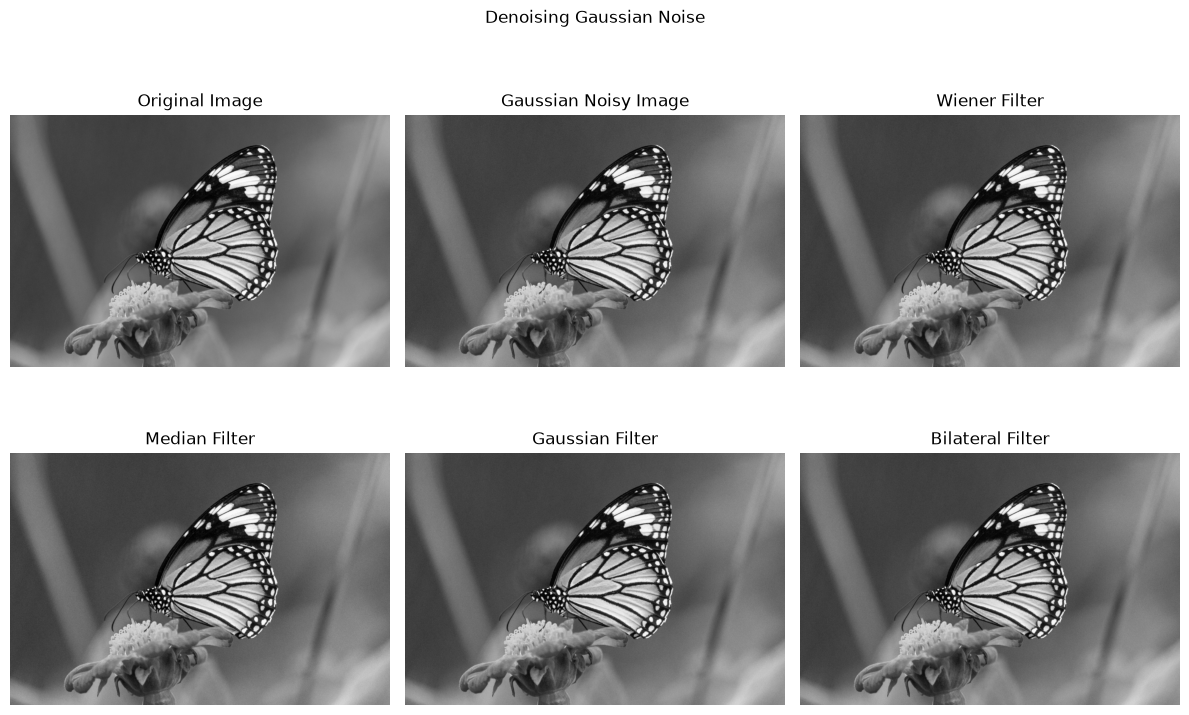

In [ ]:
#Write a program to denoise the input image corrupted by Gaussian and
#Speckle noise by using following filters (3x3 or 5x5 window).
#(a) Weiner filter
#(b) Median filtering
#(c) Gaussian filter
#(d) Bilateral filter
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import wiener

# Read grayscale image
img = cv2.imread("image.jpg", 0)

# Convert image into float
img = img / 255.0

# Select filter size
size = int(input("Enter filter size (3 or 5): "))

# Generate Gaussian noise
gaussian_noise = np.random.normal(0, 0.05, img.shape)
gaussian_img = np.clip(img + gaussian_noise, 0, 1)

# Generate Speckle noise
speckle_noise = np.random.normal(0, 0.1, img.shape)
speckle_img = np.clip(img + (img * speckle_noise), 0, 1)

# Convert noisy images to uint8
gaussian_img = np.uint8(gaussian_img * 255)
speckle_img = np.uint8(speckle_img * 255)


# Function to apply filters
def apply_filters(noisy_img):

    # Wiener filter
    # Wiener filter
    wiener_img = wiener(noisy_img.astype(float), (size, size))

    wiener_img = np.nan_to_num(wiener_img, nan=0, posinf=255, neginf=0)

    wiener_img = np.uint8(np.clip(wiener_img, 0, 255))

    # Median filter
    median_img = cv2.medianBlur(noisy_img, size)

    # Gaussian filter
    gaussian_filtered = cv2.GaussianBlur(
        noisy_img, (size, size), 0
    )

    # Bilateral filter
    bilateral_img = cv2.bilateralFilter(
        noisy_img, size, 75, 75
    )

    return wiener_img, median_img, gaussian_filtered, bilateral_img


# Apply filters to Gaussian noisy image
g1, g2, g3, g4 = apply_filters(gaussian_img)

# Apply filters to Speckle noisy image
s1, s2, s3, s4 = apply_filters(speckle_img)


# Display Gaussian noise results
plt.figure(figsize=(12, 8))

images = [
    img, gaussian_img, g1, g2, g3, g4
]

titles = [
    "Original Image",
    "Gaussian Noisy Image",
    "Wiener Filter",
    "Median Filter",
    "Gaussian Filter",
    "Bilateral Filter"
]

for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.suptitle("Denoising Gaussian Noise")
plt.tight_layout()
plt.show()


# Display Speckle noise results
plt.figure(figsize=(12, 8))

images = [
    img, speckle_img, s1, s2, s3, s4
]

titles = [
    "Original Image",
    "Speckle Noisy Image",
    "Wiener Filter",
    "Median Filter",
    "Gaussian Filter",
    "Bilateral Filter"
]

for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.suptitle("Denoising Speckle Noise")
plt.tight_layout()
plt.show()